In [1]:
print("CHAMP IS BACK")

CHAMP IS BACK


# Linear SVM Classification

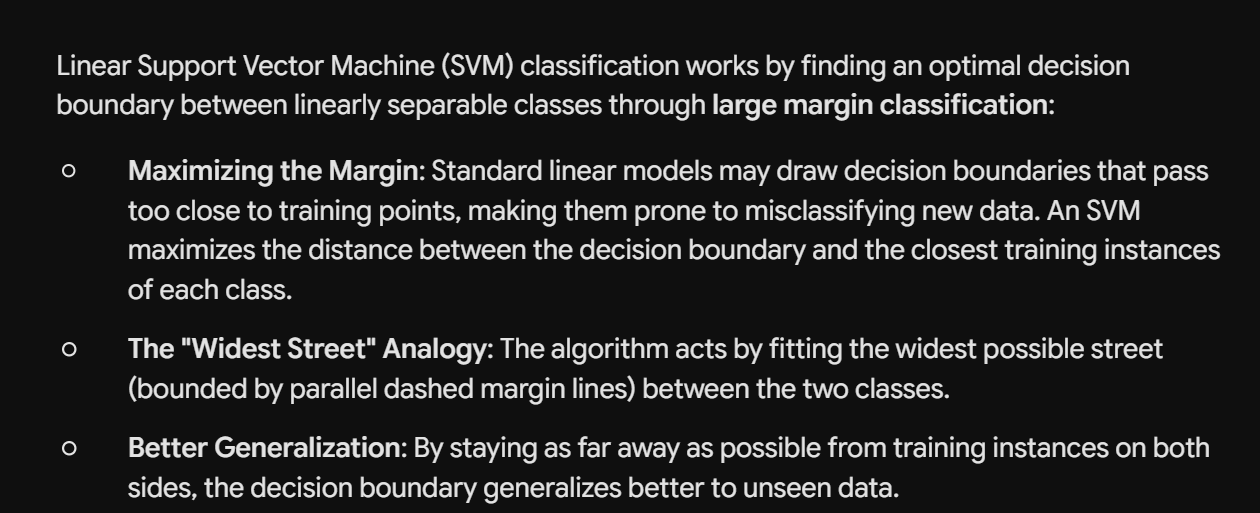

this works on the principle of large margin classification

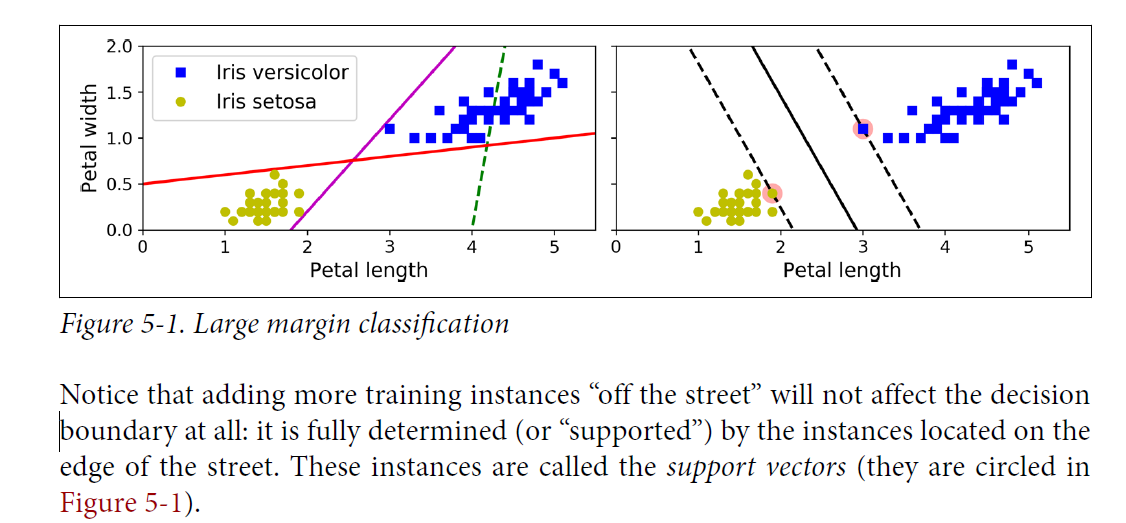

# Soft Margin Classification

If we strictly impose that all instances must be off the street and on the right side, this
is called hard margin classification. 

the issues are the following - (1) works only on linearly seprable data
(2) it is sensitive to outliers 

to fix this we need to find a more flexible model s.t.  (1) good balance between keeping the street as large as possible and (2) limiting the margin violations ; this here is called soft margin classification 

When creating an SVM model using Scikit-Learn, we can specify a number of hyperparameters.
C is one of those hyperparameters. If we set it to a low value, then we end
up with the model on the left of Figure 5-4. With a high value, we get the model on
the right. Margin violations are bad. It’s usually better to have few of them. However,
in this case the model on the left has a lot of margin violations but will probably generalize
better.

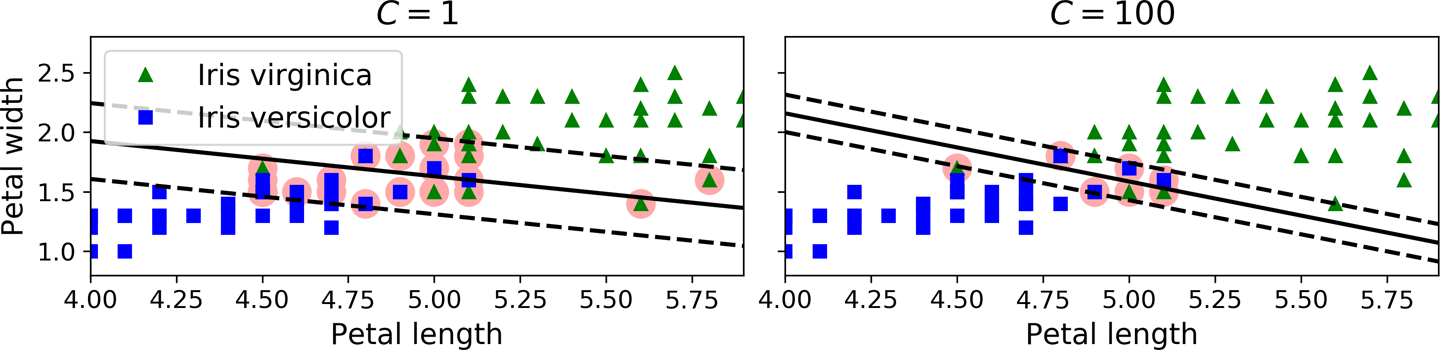

In [3]:
#code to load the iris dataset and train a linear SVM classifier to detect iris virginica flower :
#the pipeline first scales the features then a LinearSVC with c = 1:

from sklearn.datasets import load_iris
from sklearn.pipeline import make_pipeline 
from sklearn.preprocessing import StandardScaler 
from sklearn.svm import LinearSVC  # <-- Added missing import


iris = load_iris(as_frame = True)
X = iris.data[["petal length (cm)" , "petal width (cm)" ]].values
y = (iris.target == 2 ) # iris virginica 

svm_clf = make_pipeline(StandardScaler() , LinearSVC(C = 1 , random_state = 42 ))
svm_clf.fit(X,y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('linearsvc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [4]:
X_new = [[5.5 , 1.7], [5.0,1.5]]
svm_clf.predict(X_new)

array([ True, False])

let's check what were the scores given by the svm used to make these predictions , these measure the signed distance between each instance and the decision boundary 

In [5]:
svm_clf.decision_function(X_new)

array([ 0.66163816, -0.22035761])

unlike the logistic regression , LinearSVC doesn't have a predict_proba() method to give the probablity ; to give class probablities ; for this we use SVC Class if u set its probablity hyperparameter to True the model will fit an extra model to map the SVM desicion function 

# Non Linear SVM classificartion 

many datasets are non linearn so nonlinear is important ; one approach to handle this is adding more features like in polynomial regression and in some cases this solves the issue let's first implement this 

In [10]:
from sklearn.datasets import make_moons 
from sklearn.preprocessing import PolynomialFeatures 

X , y = make_moons(n_samples = 100 , noise = 0.15 , random_state = 42)

polynomial_svm_clf = make_pipeline(
    PolynomialFeatures(degree = 3),
    StandardScaler(),
    LinearSVC(C = 10 , max_iter = 10_000 , random_state = 42 )
)

polynomial_svm_clf.fit (X,y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('polynomialfeatures', ...), ('standardscaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",3
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",True
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


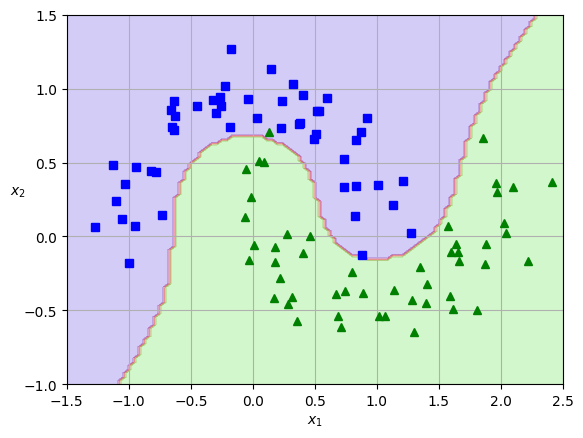

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a grid of points to evaluate the model
x0s = np.linspace(-1.5, 2.5, 100)
x1s = np.linspace(-1.0, 1.5, 100)
x0, x1 = np.meshgrid(x0s, x1s)
X_grid = np.c_[x0.ravel(), x1.ravel()]

# 2. Get predictions for the grid
y_pred = polynomial_svm_clf.predict(X_grid).reshape(x0.shape)

# 3. Plot the decision boundary contours
plt.contourf(x0, x1, y_pred, cmap=plt.cm.brg, alpha=0.2)

# 4. Plot the original dataset points
plt.plot(X[:, 0][y==0], X[:, 1][y==0], "bs")
plt.plot(X[:, 0][y==1], X[:, 1][y==1], "g^")

# 5. Format the chart
plt.axis([-1.5, 2.5, -1, 1.5])
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$", rotation=0)
plt.grid(True)
plt.show()